# RutaLog Perú · Modelos de Machine Learning

Proyecto final · Caso 14 · Victor Serrano.

Este notebook entrena los modelos de la ficha con un **histórico simulado** de 12 semanas
(*"Todos los datos del proyecto son simulados"*). El histórico lo genera `ml/generar-historico.js`
a partir de las mismas 27 rutas y 5 zonas de la API.

| Modelo | Pregunta | Tipo | Métrica |
|---|---|---|---|
| **ML-01** Riesgo de entrega fallida | ¿Esta entrega va a fallar? | Clasificación | Recall de fallidas |
| **ML-02** Tiempo estimado de entrega | ¿Cuándo llegará este envío? | Regresión | MAE en horas |
| **ML-03** Pronóstico de volumen | ¿Cuántos envíos habrá mañana por zona? | Serie de tiempo | MAPE |
| **ML-04** Orden de paradas | ¿En qué orden visitar las paradas? | Heurística | Km ahorrados |

> Ética del caso: las predicciones **orientan**; la decisión final la toma una persona (el operador).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (confusion_matrix, mean_absolute_error, precision_score, recall_score,
                             roc_auc_score)
from sklearn.preprocessing import StandardScaler

DATOS = Path('datos')
MODELOS = Path('modelos'); MODELOS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
np.random.seed(42)

envios = pd.read_csv(DATOS / 'envios.csv')
intentos = pd.read_csv(DATOS / 'intentos.csv')
volumen = pd.read_csv(DATOS / 'volumen_diario.csv', parse_dates=['fecha'])
print(f'{len(envios):,} envíos · {len(intentos):,} intentos de entrega · {len(volumen)} días')

5,170 envíos · 5,555 intentos de entrega · 84 días


## 1. Exploración del histórico

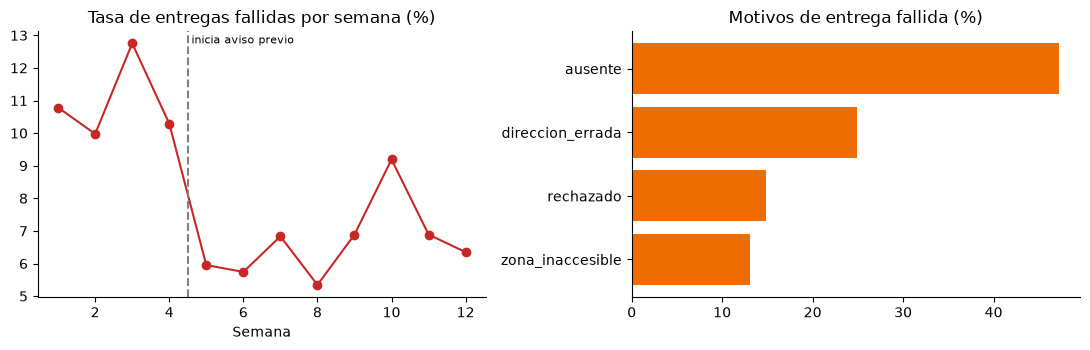

Fallidas (%) por día y franja horaria:


franja,8,10,12,14,16,18
Dom,15.1,10.2,8.8,7.2,11.6,13.4
Lun,12.1,15.8,13.7,4.8,6.6,12.7
Mar,8.3,6.9,6.1,4.1,4.2,4.1
Mié,12.5,7.0,6.1,5.0,8.4,8.3
Jue,11.7,6.2,5.5,3.6,10.7,8.8
Vie,11.6,6.0,7.6,7.4,5.4,9.1
Sáb,9.9,7.5,6.6,5.3,6.4,9.5


In [2]:
por_semana = intentos.groupby('semana')['fallo'].mean() * 100
motivos = intentos.loc[intentos.fallo == 1, 'motivo'].value_counts(normalize=True) * 100

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].plot(por_semana.index, por_semana.values, marker='o', color='#c62828')
ejes[0].axvline(4.5, ls='--', color='gray'); ejes[0].text(4.6, por_semana.max(), 'inicia aviso previo', fontsize=8)
ejes[0].set(title='Tasa de entregas fallidas por semana (%)', xlabel='Semana')
ejes[1].barh(motivos.index[::-1], motivos.values[::-1], color='#ef6c00')
ejes[1].set(title='Motivos de entrega fallida (%)')
plt.tight_layout(); plt.show()

franja_dia = intentos.pivot_table(index='dia_semana', columns='franja', values='fallo', aggfunc='mean') * 100
franja_dia.index = ['Dom', 'Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb']
print('Fallidas (%) por día y franja horaria:')
franja_dia.round(1)

## 2. ML-01 · Riesgo de entrega fallida (clasificación)

**Variables** (las de la ficha): franja horaria, zona, intentos previos, contraentrega, monto, historial
del destinatario, confirmación previa del horario; más la carga del courier y el sábado.

**Validación temporal**: se entrena con las semanas 1 a 9 y se evalúa con las semanas 10 a 12
(como en la realidad: se predice el futuro con el pasado).

**Métrica principal: recall de fallidas**, porque lo caro es *no avisar* a una entrega que iba a fallar.

In [3]:
def variables_riesgo(df):
    X = pd.DataFrame({
        'contraentrega': df.contraentrega,
        'monto_miles': df.monto_contraentrega / 1000,
        'intentos_previos': df.numero_intento - 1,
        'fallas_previas_destinatario': df.fallas_previas_destinatario.clip(upper=3),
        'confirmo_horario': df.confirmo_horario,
        'courier_sobrecargado': (df.carga_courier > 26).astype(int),
        'sabado': (df.dia_semana == 6).astype(int),
    })
    for f in [8, 10, 16, 18]:  # 12 y 14 h son la referencia
        X[f'franja_{f}h'] = (df.franja == f).astype(int)
    for z in ['Norte', 'Centro', 'Sur', 'Oriente']:  # Lima y Callao es la referencia
        X[f'zona_{z}'] = (df.zona == z).astype(int)
    return X

X, y = variables_riesgo(intentos), intentos.fallo
entreno, prueba = intentos.semana <= 9, intentos.semana >= 10
print(f'Entrenamiento: {entreno.sum():,} intentos · Prueba: {prueba.sum():,} · fallidas en prueba: {y[prueba].mean():.1%}')

Entrenamiento: 4,126 intentos · Prueba: 1,429 · fallidas en prueba: 7.4%


In [4]:
escala = StandardScaler().fit(X[entreno])
logistica = LogisticRegression(max_iter=2000).fit(escala.transform(X[entreno]), y[entreno])
bosque = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced',
                                random_state=42, n_jobs=-1).fit(X[entreno], y[entreno])

p_log = logistica.predict_proba(escala.transform(X[prueba]))[:, 1]
p_rf = bosque.predict_proba(X[prueba])[:, 1]

# Umbral de "riesgo alto": el que maximiza F2 (da el doble de peso al recall que a la precisión:
# es peor no avisar a una entrega que fallará que avisar de más), sin marcar más del 30 % de las entregas.
from sklearn.metrics import fbeta_score
def umbral_para_recall(y_real, p, tope=0.30):
    candidatos = [u for u in np.arange(0.02, 0.6, 0.005) if (p >= u).mean() <= tope]
    return round(float(max(candidatos, key=lambda u: fbeta_score(y_real, p >= u, beta=2))), 3)

filas = []
for nombre, p in [('Regresión logística', p_log), ('Random Forest', p_rf)]:
    u = umbral_para_recall(y[prueba], p)
    pred = p >= u
    filas.append({'modelo': nombre, 'umbral riesgo alto': u, 'recall fallidas': recall_score(y[prueba], pred),
                  'precisión': precision_score(y[prueba], pred), 'AUC': roc_auc_score(y[prueba], p),
                  '% marcadas': pred.mean()})
comparacion = pd.DataFrame(filas).set_index('modelo')
comparacion.style.format('{:.3f}')

,umbral riesgo alto,recall fallidas,precisión,AUC,% marcadas
modelo,,,,,
Regresión logística,0.110,0.566,0.306,0.797,0.137
Random Forest,0.545,0.547,0.280,0.777,0.145


Matriz de confusión (regresión logística) · filas = real, columnas = predicho
                 pred: normal  pred: riesgo alto
real: entregada          1187                136
real: fallida              46                 60


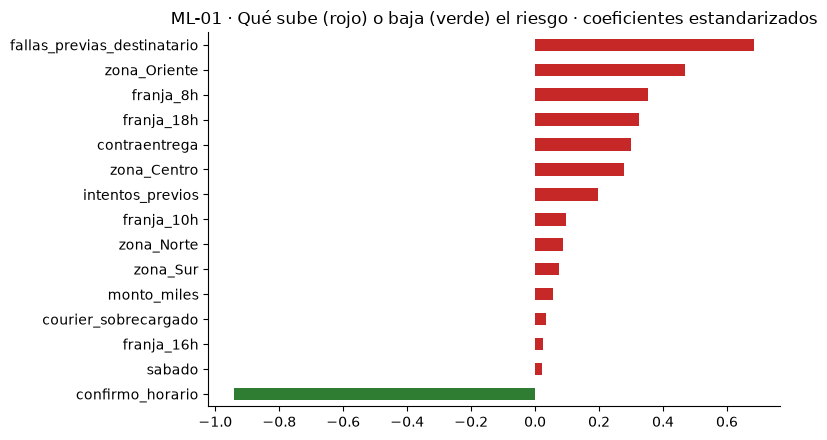

In [5]:
u_log = comparacion.loc['Regresión logística', 'umbral riesgo alto']
mc = confusion_matrix(y[prueba], p_log >= u_log)
print('Matriz de confusión (regresión logística) · filas = real, columnas = predicho')
print(pd.DataFrame(mc, index=['real: entregada', 'real: fallida'], columns=['pred: normal', 'pred: riesgo alto']))

coef = pd.Series(logistica.coef_[0], index=X.columns).sort_values()
coef.plot.barh(color=['#2e7d32' if c < 0 else '#c62828' for c in coef], figsize=(8, 4.5))
plt.title('ML-01 · Qué sube (rojo) o baja (verde) el riesgo · coeficientes estandarizados')
plt.tight_layout(); plt.show()

**Lectura:** confirmar el horario es lo que más baja el riesgo; las franjas de 8 h y 18 h, la zona Oriente,
el historial de fallas del destinatario y los reintentos lo suben. Por eso la ficha propone **avisar antes**
a las entregas con riesgo alto para que confirmen o cambien el horario.

**Modelo elegido para la App Admin: regresión logística.** Tiene un recall parecido al Random Forest,
es explicable (cada coeficiente se entiende) y se puede calcular en la API de Node sin Python:
se exportan la media y desviación de cada variable, los coeficientes y el umbral.

In [6]:
modelo_riesgo = {
    'modelo': 'ML-01 regresión logística', 'entrenado_con': 'histórico simulado, semanas 1 a 9',
    'variables': list(X.columns), 'media': escala.mean_.round(6).tolist(), 'desviacion': escala.scale_.round(6).tolist(),
    'coeficientes': logistica.coef_[0].round(6).tolist(), 'intercepto': round(float(logistica.intercept_[0]), 6),
    'umbral_riesgo_alto': u_log,
    'metricas_prueba': {k: round(float(v), 4) for k, v in comparacion.loc['Regresión logística'].items()},
}
(MODELOS / 'modelo-riesgo.json').write_text(json.dumps(modelo_riesgo, indent=2, ensure_ascii=False), encoding='utf-8')
print('Exportado modelos/modelo-riesgo.json · umbral de riesgo alto:', u_log)

Exportado modelos/modelo-riesgo.json · umbral de riesgo alto: 0.11


## 3. ML-02 · Tiempo estimado de entrega (regresión)

Se predicen las **horas desde el registro hasta la entrega**. Solo se usan datos conocidos al registrar
(no los intentos, que se conocen después). Se compara con una línea base: *tiempo de la ruta + 5 h*.

MAE línea base (ruta + 5 h): 9.4 h
MAE Gradient Boosting:       4.3 h


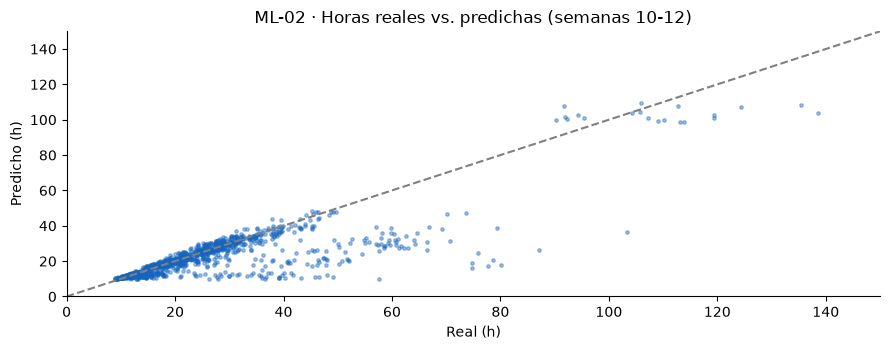

In [7]:
entregados = envios[envios.resultado == 'entregado'].copy()
def variables_tiempo(df):
    X = pd.DataFrame({'tiempo_ruta_h': df.tiempo_estimado_h, 'distancia_km': df.distancia_km, 'peso_kg': df.peso_kg,
                      'carga_courier': df.carga_courier, 'fin_de_semana': df.dia_semana.isin([0, 6]).astype(int),
                      'contraentrega': df.contraentrega})
    for z in ['Norte', 'Centro', 'Sur', 'Oriente']:
        X[f'zona_{z}'] = (df.zona == z).astype(int)
    return X

Xt, yt = variables_tiempo(entregados), entregados.horas_entrega
ent_t, pru_t = entregados.semana <= 9, entregados.semana >= 10
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, loss='absolute_error',
                                random_state=42).fit(Xt[ent_t], yt[ent_t])
pred_t = gbr.predict(Xt[pru_t])
base_t = entregados.loc[pru_t, 'tiempo_estimado_h'] + 5
print(f'MAE línea base (ruta + 5 h): {mean_absolute_error(yt[pru_t], base_t):.1f} h')
print(f'MAE Gradient Boosting:       {mean_absolute_error(yt[pru_t], pred_t):.1f} h')

plt.scatter(yt[pru_t], pred_t, s=6, alpha=0.4, color='#1565c0')
lim = [0, min(150, yt[pru_t].max())]; plt.plot(lim, lim, color='gray', ls='--')
plt.xlim(lim); plt.ylim(lim); plt.title('ML-02 · Horas reales vs. predichas (semanas 10-12)')
plt.xlabel('Real (h)'); plt.ylabel('Predicho (h)'); plt.tight_layout(); plt.show()

In [8]:
# Para la App Cliente basta una tabla: horas estimadas por ruta, entre semana y en fin de semana,
# con la carga y el peso típicos. La API la usa para mostrar la fecha estimada de entrega.
rutas = envios.groupby('ruta').agg(tiempo_estimado_h=('tiempo_estimado_h', 'first'), distancia_km=('distancia_km', 'first'),
                                   zona=('zona', 'first')).reset_index()
tabla = {}
for _, r in rutas.iterrows():
    fila = {}
    for nombre, finde in [('entre_semana', 0), ('fin_de_semana', 1)]:
        df = pd.DataFrame([{'tiempo_estimado_h': r.tiempo_estimado_h, 'distancia_km': r.distancia_km, 'peso_kg': 3.0,
                            'carga_courier': 18, 'dia_semana': 6 if finde else 2, 'contraentrega': 1, 'zona': r.zona}])
        fila[nombre] = round(float(gbr.predict(variables_tiempo(df))[0]), 1)
    tabla[r.ruta] = fila
modelo_tiempo = {'modelo': 'ML-02 Gradient Boosting', 'mae_horas_prueba': round(float(mean_absolute_error(yt[pru_t], pred_t)), 2),
                 'horas_por_ruta': tabla}
(MODELOS / 'tiempo-entrega.json').write_text(json.dumps(modelo_tiempo, indent=2, ensure_ascii=False), encoding='utf-8')
pd.DataFrame(tabla).T.sort_values('entre_semana').head(8)

,entre_semana,fin_de_semana
Lima → Callao,12.2,21.6
Lima → Lima (urbano),13.0,22.5
Lima → Ica,13.9,24.2
Arequipa → Puno,16.1,25.8
Lima → Huancayo,17.7,27.7
Lima → Cerro de Pasco,17.7,27.4
Lima → Huaraz,18.4,28.3
Lima → Huánuco,18.4,28.3


## 4. ML-03 · Pronóstico de volumen por zona (serie de tiempo)

¿Cuántos envíos habrá mañana en cada zona? Sirve para decidir **cuántos couriers programar**
(cada courier lleva hasta 30 paradas, RF-O01). Se compara un **promedio móvil de 7 días** con una
**regresión** que usa el día de la semana, la tendencia y la campaña Cyber Wow. Se evalúa con las 2 últimas semanas.

In [9]:
zonas = ['Lima y Callao', 'Norte', 'Centro', 'Sur', 'Oriente']
vol = volumen.set_index('fecha')
def mape(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    m = real > 0
    return float(np.mean(np.abs(real[m] - pred[m]) / real[m]) * 100)

def variables_volumen(fechas, inicio):
    df = pd.DataFrame(index=fechas)
    df['tendencia'] = (fechas - inicio).days
    for d in range(1, 7):
        df[f'dia_{d}'] = (fechas.day_of_week == d - 1).astype(int)  # lunes..sábado (domingo = referencia)
    df['cyber'] = ((fechas >= '2026-10-19') & (fechas <= '2026-10-23')).astype(int)
    return df

corte = vol.index.max() - pd.Timedelta(days=13)
entreno_v, prueba_v = vol[vol.index < corte], vol[vol.index >= corte]
resultado, pronostico_manana, coeficientes = [], {}, {}
manana = vol.index.max() + pd.Timedelta(days=1)
for z in zonas + ['total']:
    movil = entreno_v[z].rolling(7).mean().iloc[-1]
    reg = LinearRegression().fit(variables_volumen(entreno_v.index, vol.index.min()), entreno_v[z])
    pred = reg.predict(variables_volumen(prueba_v.index, vol.index.min()))
    resultado.append({'zona': z, 'MAPE promedio móvil (%)': mape(prueba_v[z], [movil] * len(prueba_v)),
                      'MAPE regresión (%)': mape(prueba_v[z], pred)})
    reg_total = LinearRegression().fit(variables_volumen(vol.index, vol.index.min()), vol[z])
    pronostico_manana[z] = max(0, round(float(reg_total.predict(variables_volumen(pd.DatetimeIndex([manana]), vol.index.min()))[0])))
    # Para que la API pronostique cualquier día: envíos = intercepto + Σ coeficiente × variable.
    coeficientes[z] = {'intercepto': round(float(reg_total.intercept_), 4),
                       **{n: round(float(c), 4) for n, c in zip(variables_volumen(vol.index[:1], vol.index.min()).columns, reg_total.coef_)}}
pd.DataFrame(resultado).set_index('zona').round(1)

,MAPE promedio móvil (%),MAPE regresión (%)
zona,,
Lima y Callao,38.0,17.9
Norte,105.2,55.5
Centro,33.5,21.3
Sur,38.8,28.0
Oriente,28.2,36.1
total,29.0,12.1


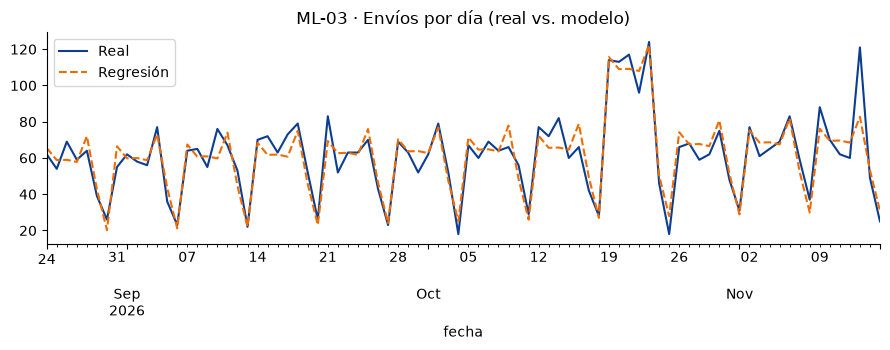

Pronóstico para 2026-11-16: {'Lima y Callao': 30, 'Norte': 14, 'Centro': 10, 'Sur': 15, 'Oriente': 9} · couriers sugeridos: {'Lima y Callao': 1, 'Norte': 1, 'Centro': 1, 'Sur': 1, 'Oriente': 1}


In [10]:
ax = vol['total'].plot(label='Real', color='#0b3d91')
reg = LinearRegression().fit(variables_volumen(vol.index, vol.index.min()), vol['total'])
pd.Series(reg.predict(variables_volumen(vol.index, vol.index.min())), index=vol.index).plot(ax=ax, label='Regresión', ls='--', color='#ef6c00')
ax.set_title('ML-03 · Envíos por día (real vs. modelo)'); ax.legend(); plt.tight_layout(); plt.show()

couriers = {z: int(np.ceil(pronostico_manana[z] / 30)) for z in zonas}
modelo_volumen = {'modelo': 'ML-03 regresión (día de la semana + tendencia + campaña)', 'fecha': str(manana.date()),
                  'envios_por_zona': {z: pronostico_manana[z] for z in zonas}, 'total': pronostico_manana['total'],
                  'couriers_sugeridos': couriers,
                  'inicio_tendencia': str(vol.index.min().date()), 'paradas_por_courier': 30,
                  'variables': 'tendencia = días desde inicio_tendencia; dia_1..dia_6 = lunes..sábado (domingo = referencia); cyber = campaña',
                  'coeficientes': coeficientes}
(MODELOS / 'pronostico-volumen.json').write_text(json.dumps(modelo_volumen, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Pronóstico para {manana.date()}:', modelo_volumen['envios_por_zona'], '· couriers sugeridos:', couriers)

## 5. ML-04 · Orden de paradas (heurística)

Ya funciona en la API (`src/rutas-optimas.js`) y en la App Courier. Se explica aquí con un ejemplo:

1. **Vecino más cercano:** desde donde está el courier, ir siempre a la parada más cercana que falta.
2. **Mejora 2-opt:** si invertir un tramo de la ruta la acorta (deshace un "cruce"), se invierte; se repite
   hasta que ya no mejora.
3. **Métrica de la ficha:** km ahorrados frente al orden de registro.

Orden de registro: 127.1 km · vecino más cercano: 60.9 km · con 2-opt: 60.9 km (52 % menos)


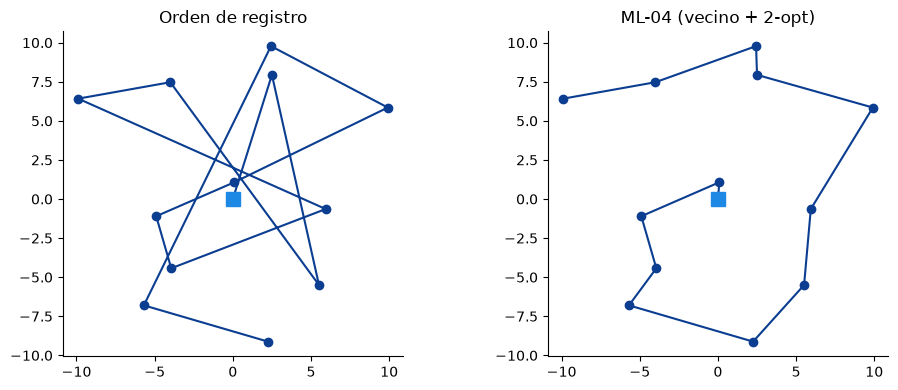

In [11]:
def dist(a, b):
    return float(np.hypot(*(np.array(a) - np.array(b))))
def largo(inicio, puntos):
    camino = [inicio] + list(puntos)
    return sum(dist(camino[i], camino[i + 1]) for i in range(len(camino) - 1))
def vecino_mas_cercano(inicio, puntos):
    pendientes, orden, actual = list(puntos), [], inicio
    while pendientes:
        siguiente = min(pendientes, key=lambda p: dist(actual, p)); orden.append(siguiente)
        pendientes.remove(siguiente); actual = siguiente
    return orden
def dos_opt(inicio, orden):
    mejor, mejoro = list(orden), True
    while mejoro:
        mejoro = False
        for i in range(len(mejor) - 1):
            for j in range(i + 1, len(mejor)):
                nuevo = mejor[:i] + mejor[i:j + 1][::-1] + mejor[j + 1:]
                if largo(inicio, nuevo) < largo(inicio, mejor) - 1e-9:
                    mejor, mejoro = nuevo, True
    return mejor

rng = np.random.default_rng(7)
inicio, paradas = (0, 0), [tuple(p) for p in rng.uniform(-10, 10, size=(12, 2)).round(2)]
nn = vecino_mas_cercano(inicio, paradas); opt = dos_opt(inicio, nn)
print(f'Orden de registro: {largo(inicio, paradas):.1f} km · vecino más cercano: {largo(inicio, nn):.1f} km · '
      f'con 2-opt: {largo(inicio, opt):.1f} km ({100 * (1 - largo(inicio, opt) / largo(inicio, paradas)):.0f} % menos)')
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, orden, titulo in [(ejes[0], paradas, 'Orden de registro'), (ejes[1], opt, 'ML-04 (vecino + 2-opt)')]:
    xs, ys = zip(*([inicio] + list(orden))); ax.plot(xs, ys, marker='o', color='#0b3d91'); ax.plot(0, 0, 's', color='#1e88e5', ms=10)
    ax.set_title(titulo); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

## 6. Conclusiones

- **ML-01** marca como **riesgo alto** a una de cada siete entregas, y ahí está más de la mitad de las fallidas
  (AUC ≈ 0.80): es unas 4 veces mejor que avisar al azar. En la App Admin esas entregas se marcan para pedir
  confirmación del horario antes de salir; en el histórico, el aviso previo bajó las fallidas de ~11 % a ~7 %.
- **ML-02** reduce el error de la fecha estimada a menos de la mitad frente a "ruta + 5 h" (MAE ≈ 4 h).
- **ML-03** pronostica el total diario con un error de ~12 % (MAPE). Por zona el error es mayor porque cada
  zona recibe pocos envíos al día (8 a 35) y el azar pesa más; por eso se usa para sugerir couriers redondeando hacia arriba.
- **ML-04** ya ordena la ruta del día en la App Courier.
- Todos los datos son simulados; con datos reales se reentrena con este mismo notebook.